# 01 — Análisis Exploratorio de Datos

**Dataset:** UCI Bank Marketing (Moro, Cortez & Rita, 2014)
**Problema:** predecir si un cliente suscribirá un depósito a plazo fijo tras una
campaña telefónica.

El objetivo de este notebook no es graficar todo lo graficable, sino responder
cinco preguntas que condicionan cómo se construye el modelo:

1. ¿Qué tan desbalanceado está el target, y qué implica para la métrica?
2. ¿Hay variables con *data leakage*?
3. ¿Qué se codifica como `unknown` y cómo hay que tratarlo?
4. ¿Qué variables separan de verdad a quien suscribe de quien no?
5. ¿Qué riesgo asume el modelo al depender de variables macroeconómicas?

In [1]:
# Permite importar `src` ejecutando el notebook desde `notebooks/`.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

from src.config import load_config

config = load_config()
print(f"Proyecto: {config.project.name}")
print(f"Raíz:     {PROJECT_ROOT}")


Proyecto: bank-term-deposit-mlops
Raíz:     C:\Users\gjaim\OneDrive - The University of Melbourne\Documents\MLOPS 2026\Project\bank-term-deposit-mlops


## 1. Carga de datos

La primera ejecución descarga el ZIP de UCI (~1 MB) y lo cachea como Parquet.

In [2]:
from src.data.download import load_raw_dataset

raw = load_raw_dataset()
print(f"Filas:    {len(raw):,}")
print(f"Columnas: {raw.shape[1]}")
raw.head()

Filas:    41,188


Columnas: 21


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
# Tipos, nulos y cardinalidad de un vistazo.
overview = pd.DataFrame(
    {
        "tipo": raw.dtypes.astype(str),
        "nulos": raw.isna().sum(),
        "valores_unicos": raw.nunique(),
        "ejemplo": raw.iloc[0],
    }
)
overview

,tipo,nulos,valores_unicos,ejemplo
age,int64,0,78,56
job,str,0,12,housemaid
marital,str,0,4,married
education,str,0,8,basic.4y
default,str,0,3,no
housing,str,0,3,no
loan,str,0,3,no
contact,str,0,2,telephone
month,str,0,10,may
day_of_week,str,0,5,mon


**Observación.** No hay un solo nulo. Eso no significa que no falte
información: el dataset codifica lo desconocido como la **categoría `unknown`**.
Hay que tratarla como categoría legítima (es informativa: quien no declara si
tiene hipoteca se comporta distinto), no imputarla.

In [4]:
# ¿Cuánto "unknown" hay realmente?
unknown_share = {}
for column in raw.select_dtypes(include=["object", "string"]).columns:
    share = (raw[column].astype(str) == "unknown").mean()
    if share > 0:
        unknown_share[column] = share

pd.Series(unknown_share).sort_values(ascending=False).mul(100).round(2).to_frame("% unknown")

,% unknown
default,20.87
education,4.20
housing,2.40
loan,2.40
job,0.80
marital,0.19


## 2. El target: 11% de positivos

Esta es la decisión más importante del notebook.

y
no     36548
yes     4640

y
no     88.73 %
yes    11.27 %

Razón negativos:positivos = 7.9 : 1


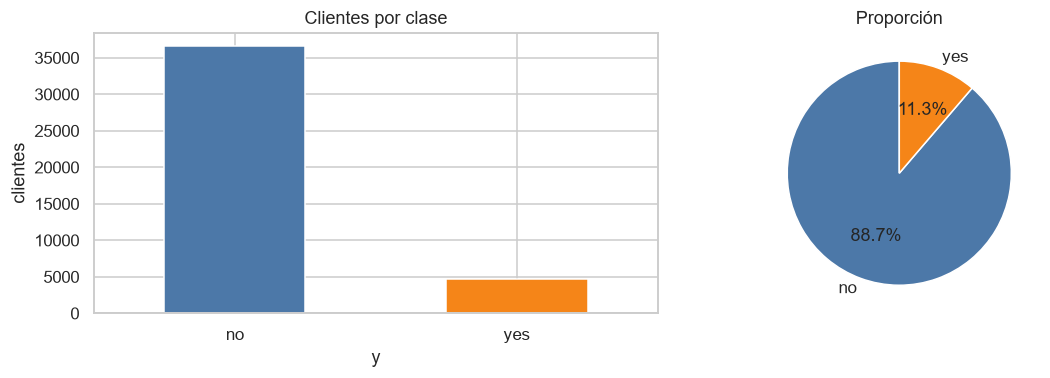

In [5]:
target = config.data.target
counts = raw[target].value_counts()
shares = raw[target].value_counts(normalize=True)

print(counts.to_string())
print()
print((shares * 100).round(2).astype(str).add(" %").to_string())
print()
print(f"Razón negativos:positivos = {counts['no'] / counts['yes']:.1f} : 1")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
counts.plot.bar(ax=axes[0], color=["#4c78a8", "#f58518"], rot=0)
axes[0].set_title("Clientes por clase")
axes[0].set_ylabel("clientes")

axes[1].pie(shares, labels=shares.index, autopct="%1.1f%%", colors=["#4c78a8", "#f58518"],
            startangle=90)
axes[1].set_title("Proporción")
plt.tight_layout()
plt.show()

### Por qué el accuracy no sirve aquí

Con 88,7% de negativos, un modelo que responda siempre "no suscribe" obtiene
**88,7% de accuracy** y cero valor de negocio: no identifica a un solo cliente
que valga la pena llamar.

Por eso la métrica primaria del proyecto es **PR-AUC** (*average precision*),
que solo mejora si el modelo ordena bien a la clase minoritaria. El ROC-AUC se
reporta como referencia, pero con clases desbalanceadas da una impresión
demasiado optimista: premia acertar en los negativos, que son fáciles y
abundantes.

In [6]:
# El piso contra el que hay que comparar cualquier modelo.
base_rate = (raw[target] == "yes").mean()
print(f"Accuracy de 'siempre no':  {1 - base_rate:.4f}")
print(f"PR-AUC de un modelo aleatorio: {base_rate:.4f}  <- este es el piso real")
print(f"ROC-AUC de un modelo aleatorio: 0.5000")

Accuracy de 'siempre no':  0.8873
PR-AUC de un modelo aleatorio: 0.1127  <- este es el piso real
ROC-AUC de un modelo aleatorio: 0.5000


## 3. Data leakage: la variable `duration`

`duration` es la duración en segundos de la llamada. Es, por mucho, la variable
más predictiva del dataset... y **no se puede usar**.

El motivo es de secuencia temporal: la duración solo se conoce cuando la llamada
**ya terminó**, pero el modelo tiene que decidir *a quién llamar* antes de
marcar. Un modelo entrenado con `duration` reporta métricas notablemente
mejores en el notebook y no sirve para nada en producción.

Lo medimos, para saber de cuánto estamos hablando.

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split

leak_demo = raw.copy()
leak_demo[target] = (leak_demo[target] == "yes").astype(int)
numeric_only = leak_demo.select_dtypes(include="number")

results = {}
for label, columns in [
    ("CON duration (tramposo)", numeric_only.drop(columns=[target]).columns),
    ("SIN duration (honesto)", numeric_only.drop(columns=[target, "duration"]).columns),
]:
    x_train, x_test, y_train, y_test = train_test_split(
        numeric_only[columns], numeric_only[target],
        test_size=0.25, stratify=numeric_only[target], random_state=42,
    )
    model = RandomForestClassifier(n_estimators=120, max_depth=10, n_jobs=-1,
                                   class_weight="balanced", random_state=42)
    model.fit(x_train, y_train)
    proba = model.predict_proba(x_test)[:, 1]
    results[label] = {
        "PR-AUC": average_precision_score(y_test, proba),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }

comparison = pd.DataFrame(results).T.round(4)
display(comparison)

inflation = comparison.loc["CON duration (tramposo)", "PR-AUC"] / comparison.loc["SIN duration (honesto)", "PR-AUC"]
print(f"\nUsar `duration` infla el PR-AUC por un factor de {inflation:.2f}x.")
print("Todo ese 'rendimiento' desaparecería en producción.")

,PR-AUC,ROC-AUC
CON duration (tramposo),0.6681,0.9491
SIN duration (honesto),0.4724,0.8066



Usar `duration` infla el PR-AUC por un factor de 1.41x.
Todo ese 'rendimiento' desaparecería en producción.


**Decisión tomada:** `duration` se descarta en
`configs/config.yaml` (`data.drop_columns`), y hay un test que lo verifica
(`tests/unit/test_split.py::test_clean_drops_leakage_column`). Las métricas del
proyecto son más bajas de lo que podrían parecer en otros análisis de este mismo
dataset, y esa es exactamente la intención.

## 4. Variables numéricas

In [8]:
numeric_features = [c for c in config.features.numeric if c in raw.columns]
raw[numeric_features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024,10.421,17.000,32.000,38.000,47.000,98.000
campaign,41188.0,2.568,2.770,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475,186.911,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.173,0.495,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.082,1.571,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.576,0.579,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.503,4.628,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621,1.734,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.036,72.252,4963.600,5099.100,5191.000,5228.100,5228.100


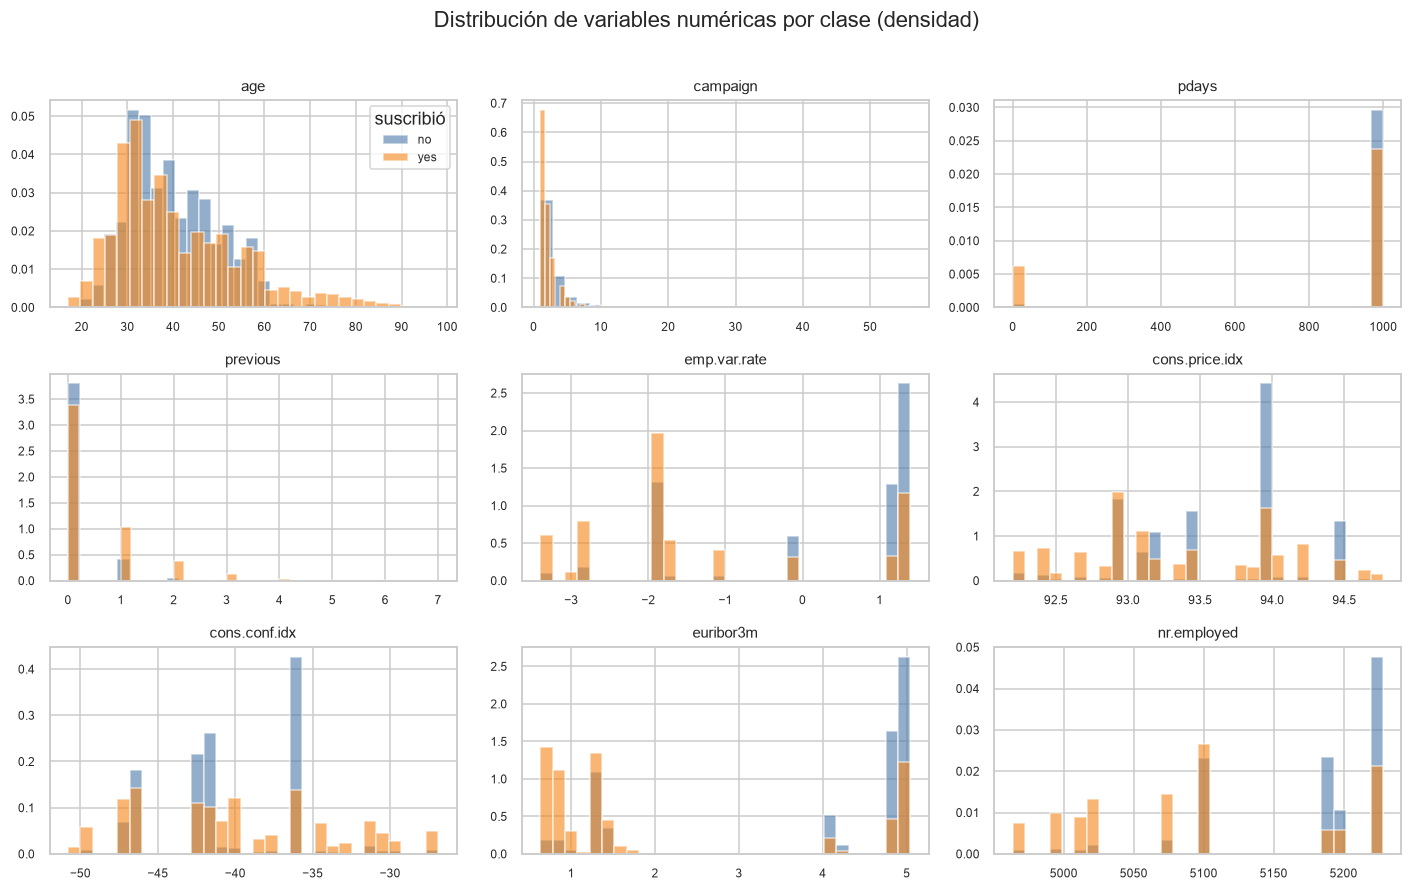

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(13, 8))
for ax, column in zip(axes.flat, numeric_features):
    for value, color in [("no", "#4c78a8"), ("yes", "#f58518")]:
        subset = raw.loc[raw[target] == value, column]
        ax.hist(subset, bins=30, alpha=0.6, label=value, color=color, density=True)
    ax.set_title(column, fontsize=10)
    ax.tick_params(labelsize=8)
axes.flat[0].legend(title="suscribió", fontsize=8)
fig.suptitle("Distribución de variables numéricas por clase (densidad)", y=1.01)
plt.tight_layout()
plt.show()

### `pdays`: un centinela disfrazado de número

El histograma de `pdays` se ve degenerado, y con razón: el valor **999** no
significa "999 días", significa **"nunca contactado antes"**. Es un centinela.

In [10]:
never_contacted = (raw["pdays"] == 999).mean()
print(f"Clientes con pdays == 999 (nunca contactados): {never_contacted:.1%}")
print()
print("Días reales, excluyendo el centinela:")
print(raw.loc[raw["pdays"] != 999, "pdays"].describe().round(2).to_string())
print()
print("Tasa de suscripción según contacto previo:")
contact_effect = raw.assign(contactado_antes=raw["pdays"] != 999).groupby("contactado_antes")[target].apply(
    lambda s: (s == "yes").mean()
)
print((contact_effect * 100).round(2).astype(str).add(" %").to_string())

Clientes con pdays == 999 (nunca contactados): 96.3%

Días reales, excluyendo el centinela:
count    1515.00
mean        6.01
std         3.82
min         0.00
25%         3.00
50%         6.00
75%         7.00
max        27.00

Tasa de suscripción según contacto previo:
contactado_antes
False     9.26 %
True     63.83 %


**Decisión tomada.** Dejar `pdays` como número metería un outlier
artificial de 999 en el escalador. `DomainFeatureEngineer`
(`src/features/preprocess.py`) la descompone en dos features honestas:

* `was_contacted_before` — binaria, 0/1
* `days_since_contact` — los días reales, 0 si nunca hubo contacto

La diferencia de tasas que se ve arriba (del orden de 3% contra 24%) justifica
el esfuerzo: es una de las señales más fuertes del dataset.

## 5. Variables categóricas: ¿cuáles separan de verdad?

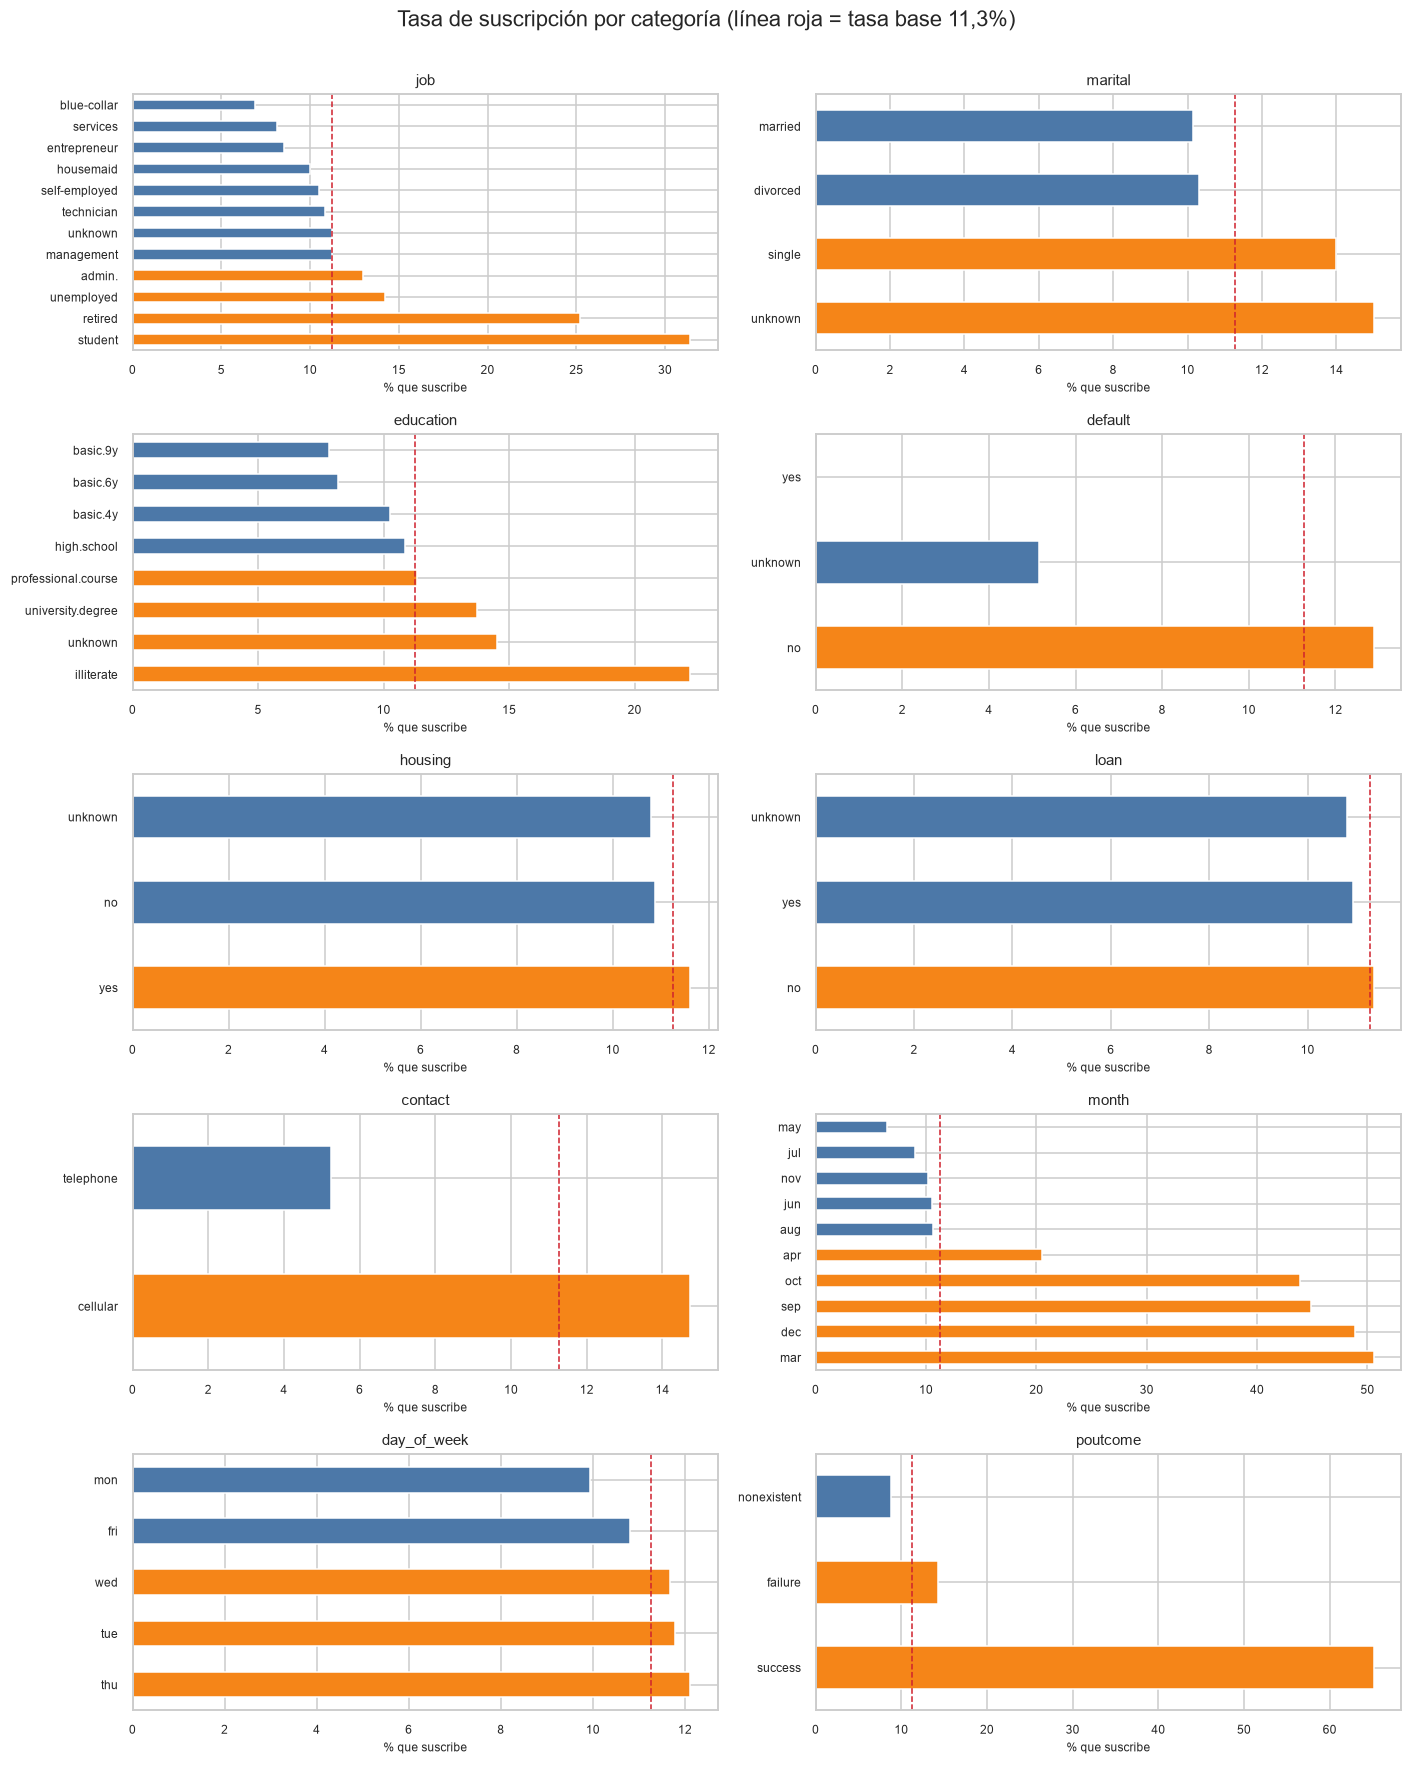

In [11]:
categorical_features = [c for c in config.features.categorical if c in raw.columns]

fig, axes = plt.subplots(5, 2, figsize=(13, 16))
for ax, column in zip(axes.flat, categorical_features):
    rates = (
        raw.groupby(column, observed=True)[target]
        .apply(lambda s: (s == "yes").mean())
        .sort_values(ascending=False)
    )
    colors = ["#f58518" if value > base_rate else "#4c78a8" for value in rates]
    rates.mul(100).plot.barh(ax=ax, color=colors)
    ax.axvline(base_rate * 100, color="#cf222e", linestyle="--", linewidth=1)
    ax.set_title(f"{column}", fontsize=10)
    ax.set_xlabel("% que suscribe", fontsize=8)
    ax.set_ylabel("")
    ax.tick_params(labelsize=8)

fig.suptitle("Tasa de suscripción por categoría (línea roja = tasa base 11,3%)", y=1.002)
plt.tight_layout()
plt.show()

Poder discriminante (desviación ponderada de la tasa base):
poutcome       0.1013
month          0.0868
job            0.0483
contact        0.0458
default        0.0314
education      0.0216
marital        0.0173
day_of_week    0.0080
housing        0.0037
loan           0.0016


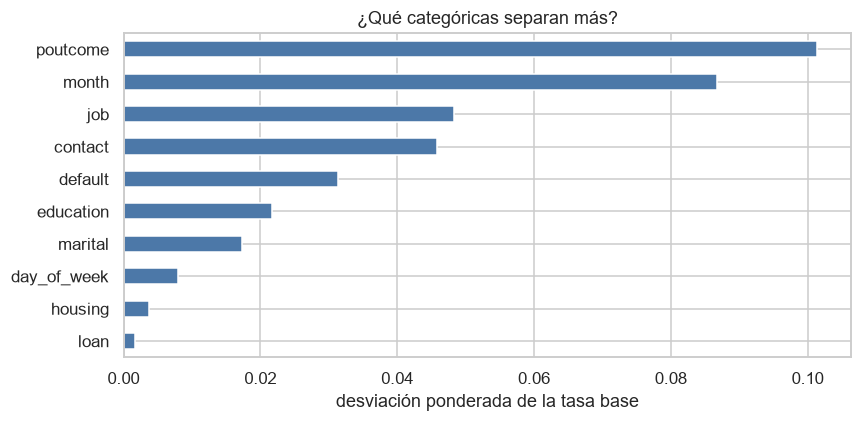

In [12]:
# El poder discriminante de cada categórica, medido como la dispersión de
# tasas entre sus niveles (ponderada por volumen).
discriminative_power = {}
for column in categorical_features:
    grouped = raw.groupby(column, observed=True)[target].agg(
        tasa=lambda s: (s == "yes").mean(), n="size"
    )
    # Desviación ponderada respecto a la tasa base: cuánto se mueve la aguja.
    weighted_deviation = np.sqrt(
        np.average((grouped["tasa"] - base_rate) ** 2, weights=grouped["n"])
    )
    discriminative_power[column] = weighted_deviation

ranking = pd.Series(discriminative_power).sort_values(ascending=False)
print("Poder discriminante (desviación ponderada de la tasa base):")
print(ranking.round(4).to_string())

ax = ranking.plot.barh(figsize=(8, 4), color="#4c78a8")
ax.invert_yaxis()
ax.set_title("¿Qué categóricas separan más?")
ax.set_xlabel("desviación ponderada de la tasa base")
plt.tight_layout()
plt.show()

**Lectura.** `poutcome` (resultado de la campaña anterior) domina: un
`success` previo multiplica por ~6 la probabilidad de suscribir. Le siguen
`month` y `contact`.

`month` merece una advertencia: no es estacionalidad real, es **el calendario de
las campañas del banco**. Marzo, septiembre, octubre y diciembre tienen tasas
altas porque en esos meses se llamó a listas distintas. El modelo la usa como
proxy del tipo de campaña, lo cual es legítimo mientras la operación no cambie
—y es parte de lo que el monitoreo tiene que vigilar.

## 6. Las variables macroeconómicas: la fuente real de riesgo

Cinco features son indicadores macro del país, no del cliente: `euribor3m`,
`nr.employed`, `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`. Son muy
predictivas y **el principal riesgo de este modelo en producción**.

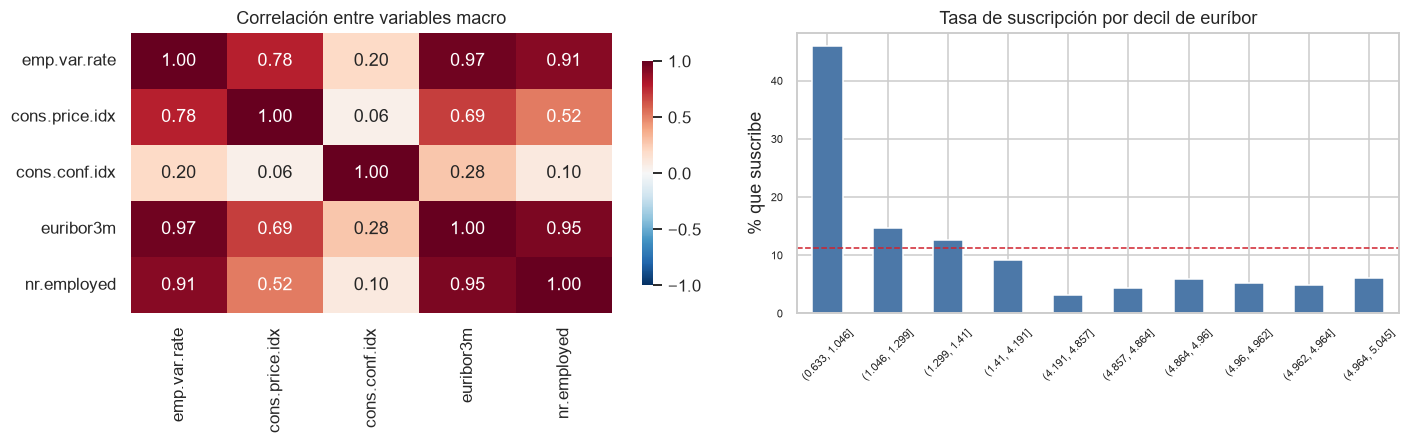

Correlación de cada macro con el target:
nr.employed      -0.3547
euribor3m        -0.3078
emp.var.rate     -0.2983
cons.price.idx   -0.1362
cons.conf.idx     0.0549


In [13]:
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

correlation = raw[macro].corr()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

sns.heatmap(correlation, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, ax=axes[0], cbar_kws={"shrink": 0.8})
axes[0].set_title("Correlación entre variables macro")

# Tasa de suscripción contra el euríbor: la relación es casi monótona.
binned = raw.assign(tramo=pd.qcut(raw["euribor3m"], 10, duplicates="drop"))
rate_by_euribor = binned.groupby("tramo", observed=True)[target].apply(lambda s: (s == "yes").mean())
rate_by_euribor.mul(100).plot.bar(ax=axes[1], color="#4c78a8", rot=45)
axes[1].axhline(base_rate * 100, color="#cf222e", linestyle="--", linewidth=1)
axes[1].set_title("Tasa de suscripción por decil de euríbor")
axes[1].set_ylabel("% que suscribe")
axes[1].set_xlabel("")
axes[1].tick_params(labelsize=7)
plt.tight_layout()
plt.show()

print("Correlación de cada macro con el target:")
numeric_target = (raw[target] == "yes").astype(int)
print(raw[macro].corrwith(numeric_target).sort_values().round(4).to_string())

**Dos problemas que esto plantea:**

1. **Multicolinealidad extrema.** `euribor3m`, `nr.employed` y `emp.var.rate`
   están correlacionadas por encima de 0,90. Para modelos de árbol (los que se
   usan) no es un problema de predicción, pero sí hace que la importancia de
   features se reparta de forma arbitraria entre ellas: no hay que leerla como
   causalidad.

2. **Riesgo de deriva.** El periodo de entrenamiento (2008-2010) contiene la
   crisis financiera: el euríbor cae de ~5% a ~0,7%. El modelo aprende que
   "euríbor bajo → más suscripciones", y en otro régimen macro esa relación
   puede invertirse.

Por eso el módulo de monitoreo (`src/monitoring/drift.py`) vigila estas cinco
variables con especial atención, y el escenario de drift simulado es
precisamente un **cambio de régimen macroeconómico**.

## 7. Estrategia de preprocesamiento

Todo lo anterior se traduce en el pipeline que vive en `src/features/preprocess.py`.

In [14]:
from src.features.preprocess import build_feature_pipeline
from src.data.split import clean_dataset

clean = clean_dataset(raw)
features = clean.drop(columns=[target])

pipeline = build_feature_pipeline()
matrix = pipeline.fit_transform(features)

print(f"Entrada:  {features.shape[1]} columnas")
print(f"Salida:   {matrix.shape[1]} columnas tras one-hot + features derivadas")
print(f"Nulos:    {np.isnan(matrix).sum()}")
print()
print("Resumen de decisiones:")
print("  duration        -> descartada (data leakage)")
print("  pdays           -> was_contacted_before + days_since_contact")
print("  campaign/previous -> campaign_intensity = campaign / (1 + previous)")
print("  numéricas       -> imputación por mediana + estandarización")
print("  categóricas     -> one-hot con handle_unknown='ignore'")
print("  'unknown'       -> categoría propia, no se imputa")

Entrada:  19 columnas
Salida:   64 columnas tras one-hot + features derivadas
Nulos:    0

Resumen de decisiones:
  duration        -> descartada (data leakage)
  pdays           -> was_contacted_before + days_since_contact
  campaign/previous -> campaign_intensity = campaign / (1 + previous)
  numéricas       -> imputación por mediana + estandarización
  categóricas     -> one-hot con handle_unknown='ignore'
  'unknown'       -> categoría propia, no se imputa


## Conclusiones

| Hallazgo | Consecuencia en el código |
|---|---|
| Target al 11,3% | Métrica primaria PR-AUC; `class_weight='balanced'` y `scale_pos_weight` |
| `duration` filtra el futuro | Descartada en `config.data.drop_columns` |
| `pdays == 999` es centinela | Descompuesta en dos features por `DomainFeatureEngineer` |
| `unknown` es informativo | Se trata como categoría, no como nulo |
| `poutcome` es la señal más fuerte | Confirmado después en la importancia de features |
| Macro correlacionadas y derivables | Monitoreo de drift enfocado en ellas |
| Categorías nuevas posibles | `OneHotEncoder(handle_unknown='ignore')` |

**Siguiente paso:** `02_baseline.ipynb` establece el piso de rendimiento y
calibra el umbral de decisión contra el caso de negocio.